In [14]:
from pathlib import Path
import pandas as pd
import numpy as np

from sklearn.feature_extraction.text import (
    CountVectorizer,
    TfidfVectorizer
)

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold
)

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score
)

from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

In [15]:
file_path = Path("../data/processed/")

df_tfidf = pd.read_csv(file_path / "tweets_tfidf.csv")

print(df_tfidf.shape)

df_tfidf.head()

(47390, 3)


,sentiment,clean_text,tweet_length
0,not_cyberbullying,in other words katandandre your food was crapi...,9
1,not_cyberbullying,why is aussietv so white mkr theblock imaceleb...,14
2,not_cyberbullying,a classy whore or more red velvet cupcakes,8
3,not_cyberbullying,meh p thanks for the heads up but not too conc...,17
4,not_cyberbullying,this is an isis account pretending to be a kur...,17


In [16]:
label2id = {
    "religion": 0,
    "age": 1,
    "ethnicity": 2,
    "gender": 3,
    "other_cyberbullying": 4,
    "not_cyberbullying": 5
}

df_tfidf["label"] = df_tfidf["sentiment"].map(label2id)

X = df_tfidf["clean_text"]
y = df_tfidf["label"]

print(df_tfidf["sentiment"].value_counts())
print(df_tfidf["label"].value_counts())

sentiment
religion               7997
age                    7992
ethnicity              7958
gender                 7928
not_cyberbullying      7850
other_cyberbullying    7665
Name: count, dtype: int64
label
0    7997
1    7992
2    7958
3    7928
5    7850
4    7665
Name: count, dtype: int64


In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(37912,)
(9478,)


In [18]:
def cross_validate_model(vectorizer, model, X, y, n_splits=5):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

    accuracy_scores = []
    f1_scores = []

    for train_idx, val_idx in skf.split(X, y):
        X_train_fold = X.iloc[train_idx]
        X_val_fold = X.iloc[val_idx]

        y_train_fold = y.iloc[train_idx]
        y_val_fold = y.iloc[val_idx]

        X_train_vec = vectorizer.fit_transform(X_train_fold)
        X_val_vec = vectorizer.transform(X_val_fold)

        model.fit(X_train_vec, y_train_fold)

        preds = model.predict(X_val_vec)

        accuracy_scores.append(accuracy_score(y_val_fold, preds))
        f1_scores.append(f1_score(y_val_fold, preds, average="macro"))

    return {
        "accuracy_scores": accuracy_scores,
        "accuracy_mean": np.mean(accuracy_scores),
        "accuracy_std": np.std(accuracy_scores),
        "macro_f1_scores": f1_scores,
        "macro_f1_mean": np.mean(f1_scores),
        "macro_f1_std": np.std(f1_scores)
    }

In [19]:
bow = CountVectorizer(
    max_features=50000,
    ngram_range=(1, 2),
    min_df=3
)

lr_bow = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_bow_kFold_results = cross_validate_model(bow, lr_bow, X_train, y_train)

print(lr_bow_kFold_results)

{'accuracy_scores': [0.8246076750626401, 0.8151127522088883, 0.8187813241888684, 0.8189132155104194, 0.8181218675811132], 'accuracy_mean': 0.819107366910386, 'accuracy_std': 0.0030765416926651556, 'macro_f1_scores': [0.8241639347458518, 0.8159912707277046, 0.8202838717683263, 0.819282357437761, 0.8176538703624998], 'macro_f1_mean': 0.8194750610084288, 'macro_f1_std': 0.002761534954544551}


In [20]:
tfidf = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1, 2),
    min_df=3
)

lr_tfidf = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_tfidf_kFold_results = cross_validate_model(tfidf, lr_tfidf, X_train, y_train)

print(lr_tfidf_kFold_results)

{'accuracy_scores': [0.8268495318475537, 0.8211789529210075, 0.8224742811922976, 0.8257715642310736, 0.8216829332629912], 'accuracy_mean': 0.8235914526909847, 'accuracy_std': 0.0022837968308212263, 'macro_f1_scores': [0.8248505493952093, 0.8211125814771915, 0.823061283815572, 0.8247679516332066, 0.8196783754083145], 'macro_f1_mean': 0.8226941483458988, 'macro_f1_std': 0.0020338020643251914}


In [21]:
clf_bow = MultinomialNB()

clf_bow_kFold_results = cross_validate_model(bow, clf_bow, X_train, y_train)

print(clf_bow_kFold_results)

{'accuracy_scores': [0.7754186997230648, 0.7684293815112753, 0.7777631231864943, 0.770509100501187, 0.7703772091796359], 'accuracy_mean': 0.7724995028203315, 'accuracy_std': 0.00350026082101999, 'macro_f1_scores': [0.759324092126611, 0.7520934224485062, 0.7635127402475449, 0.7550100433067884, 0.7533373411194986], 'macro_f1_mean': 0.7566555278497897, 'macro_f1_std': 0.004211255998350392}


In [22]:
clf_tfidf = MultinomialNB()

clf_tfidf_kFold_results = cross_validate_model(tfidf, clf_tfidf, X_train, y_train)

print(clf_tfidf_kFold_results)

{'accuracy_scores': [0.7535276275880258, 0.7547144929447448, 0.7581113162753891, 0.7566605117383276, 0.7520443154840412], 'accuracy_mean': 0.7550116528061057, 'accuracy_std': 0.0021643648035946264, 'macro_f1_scores': [0.7311151648416886, 0.7320280985311799, 0.7373262943016304, 0.7340699765197337, 0.7284718700210601], 'macro_f1_mean': 0.7326022808430586, 'macro_f1_std': 0.0029689030514109542}


In [23]:
results_summary = pd.DataFrame({
    "Model": ["LR + BoW", "LR + TF-IDF", "NB + BoW", "NB + TF-IDF"],
    "Accuracy": [lr_bow_kFold_results['accuracy_mean'], lr_tfidf_kFold_results['accuracy_mean'], clf_bow_kFold_results['accuracy_mean'], clf_tfidf_kFold_results['accuracy_mean']],
    "Macro F1": [lr_bow_kFold_results['macro_f1_mean'], lr_tfidf_kFold_results['macro_f1_mean'], clf_bow_kFold_results['macro_f1_mean'], clf_tfidf_kFold_results['macro_f1_mean']]
})

results_summary = results_summary.sort_values("Macro F1", ascending=False)

results_summary

,Model,Accuracy,Macro F1
1,LR + TF-IDF,0.823591,0.822694
0,LR + BoW,0.819107,0.819475
2,NB + BoW,0.772500,0.756656
3,NB + TF-IDF,0.755012,0.732602


In [24]:
def evaluate_model(model, X_train, X_test, y_train, y_test):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    return {
        "accuracy": accuracy_score(y_test, y_pred),
        "macro_f1": f1_score(y_test, y_pred, average="macro"),
        "classification_report": classification_report(y_test, y_pred),
        "y_pred": y_pred
    }

tfidf = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1, 2),
    min_df=3
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print(X_train_tfidf.shape)
print(X_test_tfidf.shape)


(37912, 50000)
(9478, 50000)


In [25]:
lr_tfidf_train = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_tfidf_results = evaluate_model(lr_tfidf_train, X_train_tfidf, X_test_tfidf, y_train, y_test)

print(f"Accuracy: {lr_tfidf_results['accuracy']:.4f}")
print(f"Macro F1: {lr_tfidf_results['macro_f1']:.4f}")
print(lr_tfidf_results['classification_report'])

Accuracy: 0.8278
Macro F1: 0.8262
              precision    recall  f1-score   support

           0       0.94      0.95      0.95      1599
           1       0.96      0.98      0.97      1598
           2       0.97      0.98      0.97      1592
           3       0.91      0.83      0.87      1586
           4       0.59      0.67      0.63      1533
           5       0.60      0.55      0.57      1570

    accuracy                           0.83      9478
   macro avg       0.83      0.83      0.83      9478
weighted avg       0.83      0.83      0.83      9478



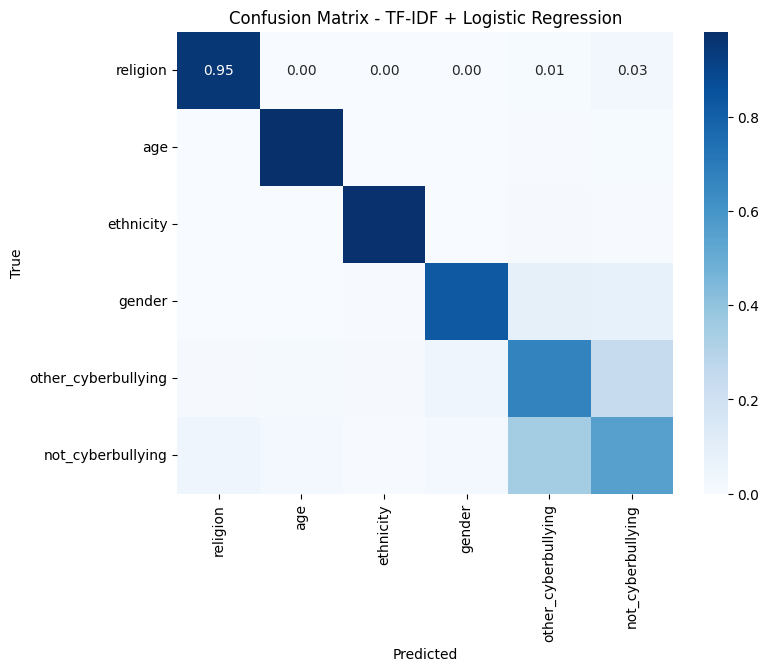

In [26]:
cm = confusion_matrix(y_test, lr_tfidf_results["y_pred"], normalize="true")

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=label2id.keys(),
    yticklabels=label2id.keys()
)

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix - TF-IDF + Logistic Regression")

plt.show()

The TF-IDF combined with Logistic Regression achieved the best baseline performance, the confusion matrix indicates that the religion, age and ethinicity are classified reliably, while most error occurs between the other_cyberbullying and not_cyberbullying classes, this suggests that these classes require greater contextual understanding than simple lexical features can provide.